# 07 · Deep Learning Sequence Data Preparation & Pipeline

In **Phase 1**, we hand-engineered 71 summary features (rolling mean, standard deviation, trend slope, and healthy baseline deviation) using fixed 10-cycle windows. While effective, manual feature engineering discards the exact temporal order of readings and requires domain tuning.

In **Phase 2**, we formulate the predictive maintenance problem as **sequence-to-target regression**: feeding a fixed-length window of raw sensor readings $X \in \mathbb{R}^{W \times 14}$ ($W = 30$ cycles) directly into sequence neural networks to learn degradation dynamics automatically without manual feature engineering.

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib_cache')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GroupShuffleSplit
import joblib
import torch
from torch.utils.data import TensorDataset, DataLoader

from utils import (
    load_raw, SEED, RUL_CAP, SEQ_LEN, USEFUL_SENSORS,
    gen_sequence_data, gen_test_sequences, savefig,
    PROCESSED_DATA, MODELS, RAW_DATA
)

np.random.seed(SEED)
torch.manual_seed(SEED)
print('PyTorch version:', torch.__version__)
print('Sequence window size (W):', SEQ_LEN)
print(f'{len(USEFUL_SENSORS)} Informative sensors kept:', USEFUL_SENSORS)

PyTorch version: 2.14.1
Sequence window size (W): 30
14 Informative sensors kept: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 1. Load Raw Sensor Data and Compute Capped RUL Target

We compute the ground truth Remaining Useful Life (RUL) for each engine cycle:
$$\text{RUL}_{i,t} = \min(125, \text{cycle}_{i,\text{max}} - \text{cycle}_{i,t})$$

Healthy engines have constant RUL capped at 125, allowing the sequence models to focus on the degradation phase.

In [2]:
train_raw = load_raw('train_FD001.txt')
test_raw = load_raw('test_FD001.txt')
rul_test = pd.read_csv(RAW_DATA / 'RUL_FD001.txt', sep=r'\s+', header=None, names=['RUL'])

train_raw['RUL_raw'] = train_raw.groupby('unit')['cycle'].transform(lambda x: x.max() - x)
train_raw['RUL'] = train_raw['RUL_raw'].clip(upper=RUL_CAP)
print(f'Train raw rows: {len(train_raw):,}, unique engines: {train_raw["unit"].nunique()}')
print(f'Test raw rows: {len(test_raw):,}, unique engines: {test_raw["unit"].nunique()}')

Train raw rows: 20,631, unique engines: 100
Test raw rows: 13,096, unique engines: 100


## 2. Engine-Level Split (Identical to Phase 1)

To ensure a strictly fair comparison with Phase 1, we use the exact same 80 training engines and 20 validation engines (`GroupShuffleSplit`, `random_state=42`). No engine appears in both train and validation.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(splitter.split(train_raw, groups=train_raw['unit']))
val_units = sorted(train_raw.iloc[val_idx]['unit'].unique())
train_units = sorted(train_raw.iloc[train_idx]['unit'].unique())

print('Training engines count:', len(train_units))
print('Validation engines count:', len(val_units))
print('Validation engine IDs:', val_units)

train_df = train_raw[train_raw['unit'].isin(train_units)].copy()
val_df = train_raw[train_raw['unit'].isin(val_units)].copy()
test_df = test_raw.copy()

Training engines count: 80
Validation engines count: 20
Validation engine IDs: [np.int64(1), np.int64(5), np.int64(11), np.int64(13), np.int64(19), np.int64(23), np.int64(31), np.int64(32), np.int64(34), np.int64(40), np.int64(45), np.int64(46), np.int64(54), np.int64(71), np.int64(74), np.int64(77), np.int64(78), np.int64(81), np.int64(84), np.int64(91)]


## 3. Sensor Normalization (Zero Data Leakage)

Deep sequence architectures (LSTM, CNN) train best when sensor features are scaled within $[-1, 1]$.
**Strict Rule:** We fit `MinMaxScaler` only on the 80 training engines and transform the validation and test sets.

In [4]:
scaler = MinMaxScaler(feature_range=(-1, 1))
train_df[USEFUL_SENSORS] = scaler.fit_transform(train_df[USEFUL_SENSORS])
val_df[USEFUL_SENSORS] = scaler.transform(val_df[USEFUL_SENSORS])
test_df[USEFUL_SENSORS] = scaler.transform(test_df[USEFUL_SENSORS])

joblib.dump(scaler, MODELS / 'dl_sensor_scaler.joblib')
print('Saved scaler to outputs/models/dl_sensor_scaler.joblib')

Saved scaler to outputs/models/dl_sensor_scaler.joblib


## 4. Sliding Window Sequence Construction (3D Tensors)

We slice each engine's time series into fixed windows of length $W = 30$:
- Input $X$: Sensors from cycle $t - 29$ to cycle $t$, shape $(30, 14)$.
- Target $y$: Capped RUL at cycle $t$.
- **Boundary constraint:** Sequences never cross engine boundaries.

In [5]:
X_train, y_train, y_raw_train, u_train = gen_sequence_data(train_df, seq_length=SEQ_LEN)
X_val, y_val, y_raw_val, u_val = gen_sequence_data(val_df, seq_length=SEQ_LEN)
X_test, u_test = gen_test_sequences(test_df, seq_length=SEQ_LEN)
y_test = rul_test['RUL'].clip(upper=RUL_CAP).values.astype(np.float32)
y_raw_test = rul_test['RUL'].values.astype(np.float32)

print('Sequence dataset summary:')
print(f'  X_train: {X_train.shape}  | y_train: {y_train.shape}')
print(f'  X_val:   {X_val.shape}  | y_val:   {y_val.shape}')
print(f'  X_test:  {X_test.shape}   | y_test:  {y_test.shape}')

Sequence dataset summary:
  X_train: (14241, 30, 14)  | y_train: (14241,)
  X_val:   (3490, 30, 14)  | y_val:   (3490,)
  X_test:  (100, 30, 14)   | y_test:  (100,)


## 5. Visualizing a Sequence Window: Healthy vs Degrading State

Let's visualize how the 14 normalized sensor readings behave inside a 30-cycle window early in engine life (healthy) versus right before failure (critical degradation).

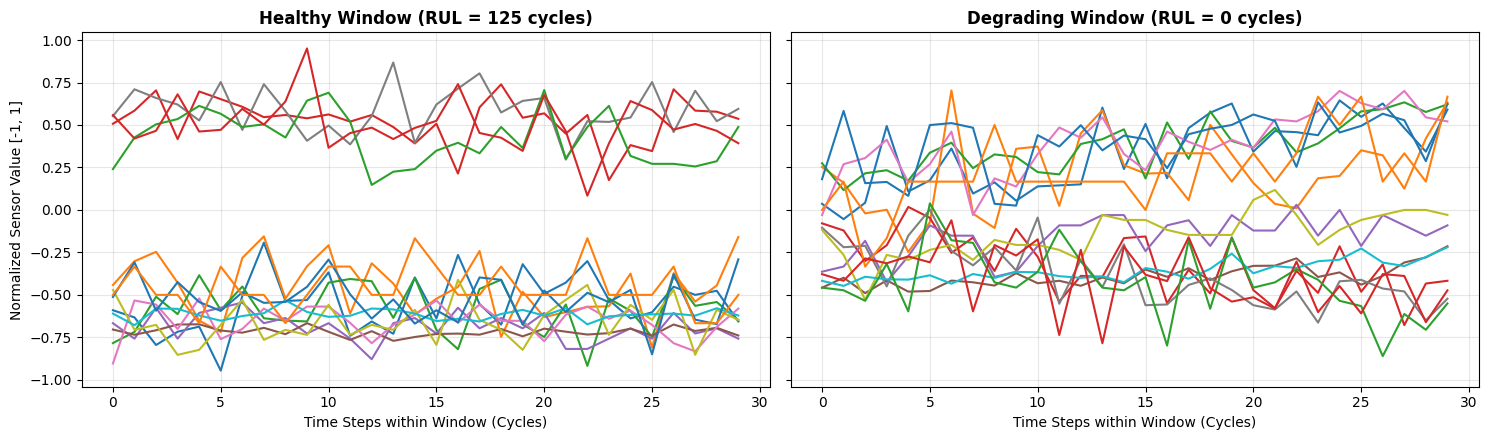

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)

# Early healthy window (first window of engine 1)
axes[0].plot(X_train[0], lw=1.5)
axes[0].set_title(f'Healthy Window (RUL = {y_train[0]:.0f} cycles)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Time Steps within Window (Cycles)')
axes[0].set_ylabel('Normalized Sensor Value [-1, 1]')
axes[0].grid(True, alpha=0.3)

# Late deteriorating window (near failure of engine 1)
last_e1_idx = np.where(u_train == train_units[0])[0][-1]
axes[1].plot(X_train[last_e1_idx], lw=1.5)
axes[1].set_title(f'Degrading Window (RUL = {y_train[last_e1_idx]:.0f} cycles)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Time Steps within Window (Cycles)')
axes[1].grid(True, alpha=0.3)

savefig('07_sequence_window_visualization')

## 6. Save Sequence Tensors for Deep Learning Models

We save the preprocessed sequence arrays into `data/processed/` for direct consumption by PyTorch models.

In [7]:
np.save(PROCESSED_DATA / 'X_train_seq.npy', X_train)
np.save(PROCESSED_DATA / 'y_train_seq.npy', y_train)
np.save(PROCESSED_DATA / 'y_raw_train_seq.npy', y_raw_train)
np.save(PROCESSED_DATA / 'u_train_seq.npy', u_train)

np.save(PROCESSED_DATA / 'X_val_seq.npy', X_val)
np.save(PROCESSED_DATA / 'y_val_seq.npy', y_val)
np.save(PROCESSED_DATA / 'y_raw_val_seq.npy', y_raw_val)
np.save(PROCESSED_DATA / 'u_val_seq.npy', u_val)

np.save(PROCESSED_DATA / 'X_test_seq.npy', X_test)
np.save(PROCESSED_DATA / 'y_test_seq.npy', y_test)
np.save(PROCESSED_DATA / 'y_raw_test_seq.npy', y_raw_test)
np.save(PROCESSED_DATA / 'u_test_seq.npy', u_test)

print('Saved all sequence arrays to data/processed/')

Saved all sequence arrays to data/processed/
